# 02 · Churn Prediction Model: Training, Explainability & Retention Actions
Predict which telecom customers will churn, explain **why** with SHAP, and estimate how much specific retention actions would lower each customer's risk.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib, json, shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
STAY, CHURN = '#2a78d6', '#eb6834'
sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/processed/churn_clean.csv')
df = df.drop(columns=['TenureGroup'], errors='ignore')
df.shape

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(7043, 21)

## 1. Feature engineering

In [2]:
SERVICES = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_features(d):
    d = d.copy()
    d['NumServices'] = (d[SERVICES] == 'Yes').sum(axis=1) + (d['PhoneService'] == 'Yes')
    d['IsNewCustomer'] = (d['tenure'] <= 12).astype(int)
    d['AutoPay'] = d['PaymentMethod'].str.contains('automatic').astype(int)
    d['HasProtection'] = ((d['OnlineSecurity'] == 'Yes') | (d['TechSupport'] == 'Yes')).astype(int)
    return d

df = add_features(df)
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices', 'IsNewCustomer', 'AutoPay', 'HasProtection']
cat_cols = [c for c in X.columns if c not in num_cols]
print(len(num_cols), 'numeric |', len(cat_cols), 'categorical')

7 numeric | 16 categorical


New features:
- **NumServices:** how many services the customer uses
- **IsNewCustomer:** tenure of 12 months or less, the highest-risk group from EDA
- **AutoPay:** pays by automatic bank transfer or credit card
- **HasProtection:** has online security or tech support

## 2. Split and leakage-free pipeline

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False), cat_cols)])
print('Train', X_train.shape, f'{y_train.mean():.1%} churn | Test', X_test.shape, f'{y_test.mean():.1%} churn')

Train (5634, 23) 26.5% churn | Test (1409, 23) 26.5% churn


## 3. Compare four models (5-fold stratified cross-validation)

In [4]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=spw, eval_metric='logloss', random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, class_weight='balanced', random_state=42, verbose=-1)}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    s = cross_validate(Pipeline([('prep', preprocess), ('model', m)]), X_train, y_train, cv=cv, scoring=['roc_auc', 'average_precision', 'recall', 'precision'])
    rows.append({'model': name, **{k[5:]: round(v.mean(), 3) for k, v in s.items() if k.startswith('test_')}})
pd.DataFrame(rows).set_index('model')

,roc_auc,average_precision,recall,precision
model,,,,
Logistic Regression,0.846,0.662,0.796,0.518
Random Forest,0.846,0.656,0.762,0.539
XGBoost,0.846,0.668,0.797,0.523
LightGBM,0.847,0.662,0.782,0.535


## 4. Hyperparameter tuning (RandomizedSearchCV on XGBoost)

In [5]:
search = RandomizedSearchCV(
    Pipeline([('prep', preprocess), ('model', XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', random_state=42, n_jobs=-1))]),
    {'model__n_estimators': [200, 300, 500], 'model__max_depth': [2, 3, 4], 'model__learning_rate': [0.02, 0.03, 0.05],
     'model__subsample': [0.7, 0.8, 1.0], 'model__colsample_bytree': [0.6, 0.8, 1.0], 'model__min_child_weight': [1, 3, 5]},
    n_iter=25, scoring='roc_auc', cv=cv, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)
print('Best params:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})
print(f'Best CV ROC-AUC: {search.best_score_:.3f}')

Best params: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
Best CV ROC-AUC: 0.850


## 5. Test-set evaluation

In [6]:
fitted = {n: Pipeline([('prep', preprocess), ('model', m)]).fit(X_train, y_train) for n, m in models.items()}
fitted['XGBoost (tuned)'] = search.best_estimator_
rows = []
for n, p in fitted.items():
    pr = p.predict_proba(X_test)[:, 1]; pd_ = (pr >= 0.5).astype(int)
    rows.append({'model': n, 'ROC-AUC': roc_auc_score(y_test, pr), 'PR-AUC': average_precision_score(y_test, pr), 'Accuracy': accuracy_score(y_test, pd_),
                 'Precision': precision_score(y_test, pd_), 'Recall': recall_score(y_test, pd_), 'F1': f1_score(y_test, pd_)})
test_results = pd.DataFrame(rows).set_index('model').round(3)
test_results

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
model,,,,,,
Logistic Regression,0.842,0.629,0.739,0.505,0.786,0.615
Random Forest,0.839,0.643,0.763,0.537,0.773,0.634
XGBoost,0.846,0.666,0.749,0.518,0.794,0.627
LightGBM,0.842,0.659,0.758,0.530,0.789,0.634
XGBoost (tuned),0.847,0.665,0.748,0.516,0.802,0.628


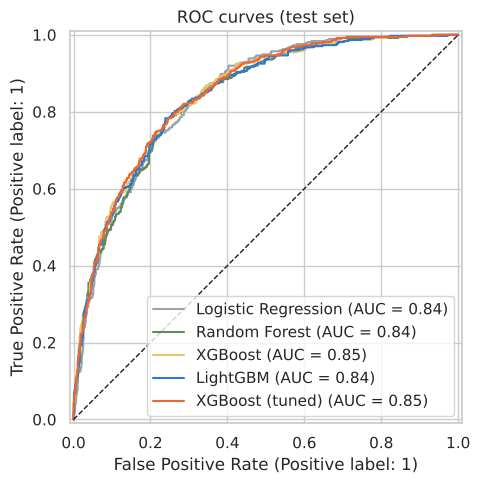

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for (n, p), c in zip(fitted.items(), ['#9aa3ad', '#5b8c5a', '#e9c46a', STAY, CHURN]):
    RocCurveDisplay.from_estimator(p, X_test, y_test, ax=ax, name=n, curve_kwargs={'color': c})
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_title('ROC curves (test set)')
plt.tight_layout(); plt.savefig('../images/08_roc_curves.png', dpi=150); plt.show()

## 6. Decision threshold
Pick the threshold that maximises F1 on out-of-fold training predictions (not on the test set).

Threshold: 0.58
              precision    recall  f1-score   support

      Stayed      0.893     0.792     0.840      1035
     Churned      0.562     0.738     0.638       374

    accuracy                          0.778      1409
   macro avg      0.728     0.765     0.739      1409
weighted avg      0.805     0.778     0.786      1409



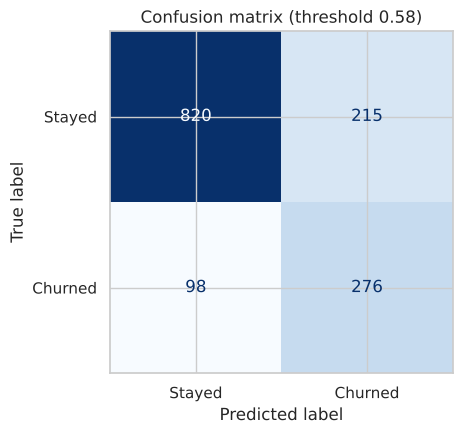

In [8]:
best = search.best_estimator_
oof = cross_val_predict(best, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
ths = np.arange(0.2, 0.81, 0.02)
threshold = float(ths[int(np.argmax([f1_score(y_train, (oof >= t).astype(int)) for t in ths]))])
proba = best.predict_proba(X_test)[:, 1]; pred = (proba >= threshold).astype(int)
print(f'Threshold: {threshold:.2f}')
print(classification_report(y_test, pred, target_names=['Stayed', 'Churned'], digits=3))
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Stayed', 'Churned']).plot(cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'Confusion matrix (threshold {threshold:.2f})'); plt.tight_layout(); plt.savefig('../images/09_confusion_matrix.png', dpi=150); plt.show()

## 7. Explainability with SHAP

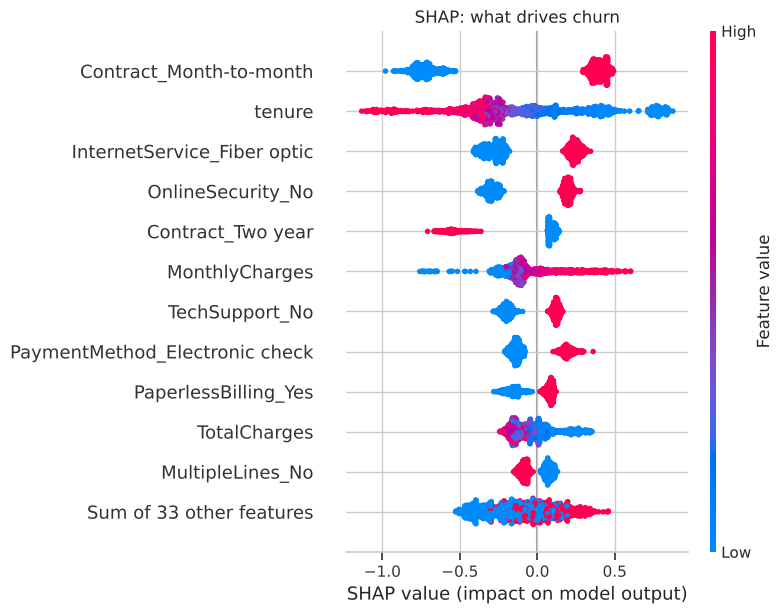

Contract_Month-to-month           0.546
tenure                            0.374
InternetService_Fiber optic       0.267
OnlineSecurity_No                 0.246
Contract_Two year                 0.204
MonthlyCharges                    0.169
TechSupport_No                    0.159
PaymentMethod_Electronic check    0.158
PaperlessBilling_Yes              0.112
TotalCharges                      0.106
dtype: float32

In [9]:
prep, xgb = best.named_steps['prep'], best.named_steps['model']
feat_names = [f.split('__', 1)[1] for f in prep.get_feature_names_out()]
X_test_t = pd.DataFrame(prep.transform(X_test), columns=feat_names)
sv = shap.TreeExplainer(xgb)(X_test_t)
plt.figure()
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title('SHAP: what drives churn'); plt.tight_layout(); plt.savefig('../images/10_shap_summary.png', dpi=150, bbox_inches='tight'); plt.show()
pd.Series(np.abs(sv.values).mean(0), index=feat_names).sort_values(ascending=False).head(10).round(3)

## 8. Risk tiers and business value

In [10]:
tiers = pd.cut(proba, [0, 0.25, 0.5, 1.0], labels=['Low (<25%)', 'Medium (25-50%)', 'High (50%+)'], include_lowest=True)
tier_table = pd.DataFrame({'tier': tiers, 'churn': y_test.values}).groupby('tier', observed=True)['churn'].agg(customers='size', actual_churn_rate='mean')
tier_table['share'] = tier_table['customers'] / tier_table['customers'].sum()
print(tier_table.round(3))
ranked = pd.DataFrame({'p': proba, 'y': y_test.values}).sort_values('p', ascending=False)
top = ranked.head(int(len(ranked) * 0.2))
print(f"\nTop 20% riskiest customers contain {top.y.sum() / ranked.y.sum():.0%} of all churners (lift {top.y.mean() / y_test.mean():.1f}x)")

                 customers  actual_churn_rate  share
tier                                                
Low (<25%)             557              0.039  0.395
Medium (25-50%)        271              0.192  0.192
High (50%+)            581              0.516  0.412

Top 20% riskiest customers contain 51% of all churners (lift 2.5x)


## 9. What-if: how much would a retention action help?
Take every high-risk customer in the test set, apply one change at a time, and re-score them with the model. This is a **model-based estimate** of each action's effect, not a measured causal effect, but it shows the retention team where to start.

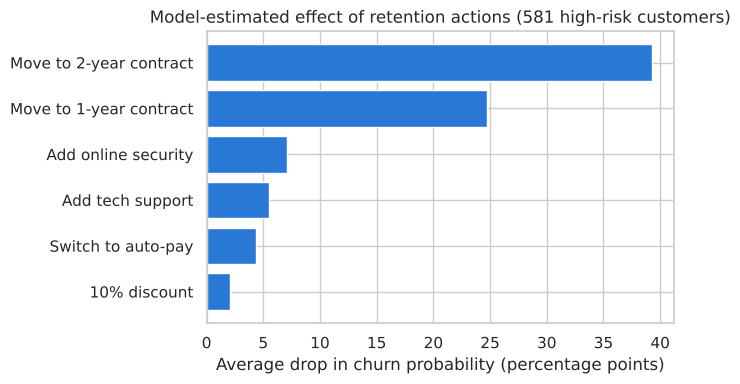

Move to 2-year contract    39.299999
Move to 1-year contract    24.799999
Add online security         7.100000
Add tech support            5.500000
Switch to auto-pay          4.300000
10% discount                2.100000
dtype: float32

In [11]:
high = X_test[proba >= 0.5].copy()
def rescore(d): return best.predict_proba(add_features(d.drop(columns=['NumServices', 'IsNewCustomer', 'AutoPay', 'HasProtection'])))[:, 1]
base = rescore(high)
actions = {
    'Move to 1-year contract': lambda d: d.assign(Contract='One year'),
    'Move to 2-year contract': lambda d: d.assign(Contract='Two year'),
    'Add tech support': lambda d: d.assign(TechSupport=np.where(d.InternetService == 'No', d.TechSupport, 'Yes')),
    'Add online security': lambda d: d.assign(OnlineSecurity=np.where(d.InternetService == 'No', d.OnlineSecurity, 'Yes')),
    'Switch to auto-pay': lambda d: d.assign(PaymentMethod='Credit card (automatic)'),
    '10% discount': lambda d: d.assign(MonthlyCharges=d.MonthlyCharges * 0.9, TotalCharges=d.TotalCharges * 0.9),
}
effect = pd.Series({a: (base - rescore(f(high.copy()))).mean() * 100 for a, f in actions.items()}).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(effect.index[::-1], effect.values[::-1], color=STAY)
ax.set_xlabel('Average drop in churn probability (percentage points)'); ax.set_title(f'Model-estimated effect of retention actions ({len(high)} high-risk customers)')
plt.tight_layout(); plt.savefig('../images/11_retention_actions.png', dpi=150); plt.show()
effect.round(1)

## 10. Save the model for the web app (portable formats)

In [12]:
best.named_steps['model'].save_model('../models/xgb_model.json')
joblib.dump(best.named_steps['prep'], '../models/preprocessor.joblib')
meta = {'threshold': round(threshold, 2), 'tiers': [0.25, 0.5],
        'test_metrics': test_results.loc['XGBoost (tuned)'].to_dict(), 'churn_rate': round(float(y.mean()), 4)}
json.dump(meta, open('../models/model_meta.json', 'w'), indent=2)
meta

{'threshold': 0.58,
 'tiers': [0.25, 0.5],
 'test_metrics': {'ROC-AUC': 0.847,
  'PR-AUC': 0.665,
  'Accuracy': 0.748,
  'Precision': 0.516,
  'Recall': 0.802,
  'F1': 0.628},
 'churn_rate': 0.2654}

## Results summary
- Compared **Logistic Regression, Random Forest, XGBoost and LightGBM** with 5-fold stratified cross-validation, then tuned XGBoost with RandomizedSearchCV.
- Set the decision threshold from out-of-fold predictions and handled the 26.5% class imbalance with class weights.
- Used **SHAP** to show that contract type, tenure, internet service and monthly charges drive churn.
- Ran **what-if simulations** that estimate how much retention actions (longer contracts, tech support, auto-pay, discounts) would lower risk.
- The saved model powers the **ChurnRadar** web app in `app/`.